In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torch.cuda.amp import GradScaler, autocast
from data.dataset import *
from data.image_generator import *
from data.mgf_parser import *
from data.spectrum_parser import *
from models.vit_model import *
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device in use: {device}")

Device in use: cuda


In [2]:
def plot_training_curves(train_losses, val_losses, train_accs, val_accs):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    
    ax1.plot(train_losses, label='Train Loss')
    ax1.plot(val_losses, label='Val Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.set_title('Training and Validation Loss')
    ax1.legend()
    ax1.grid(True)
    
    ax2.plot(train_accs, label='Train Accuracy')
    ax2.plot(val_accs, label='Val Accuracy')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy')
    ax2.set_title('Training and Validation Accuracy')
    ax2.legend()
    ax2.grid(True)
    
    plt.tight_layout()
    # plt.savefig('training_curves.png', dpi=300)
    plt.show()


def plot_confusion_matrix(labels, preds, save_path='confusion_matrix.png'):
    cm = confusion_matrix(labels, preds)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title('Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    # plt.savefig(save_path, dpi=300)
    plt.show()

In [3]:
input_directory = r'E:\UViT\data\raw\JPST002123_all_UVPD\mzml'


if not os.path.exists(input_directory):
    print(f"Error: Directory does not exist - {input_directory}")
else:
    file_groups = group_files_by_prefix(input_directory)
    if not file_groups:
        print("No processable file groups found")
    else:
        print(f"Found {len(file_groups)} file groups:")
        for prefix, files in file_groups.items():
            print(f"  - {prefix}: {len(files)} files")
        all_updated_dfs = {}
        for prefix, file_paths in file_groups.items():
            try:
                result, updated_dfs, spectra_dfs, mono_arr = process_file_group(file_paths, prefix)

                all_updated_dfs[prefix] = updated_dfs
 
            except Exception as e:
                print(f"\n✗ Error processing file group {prefix}: {e}")
                continue
        print(f"\n{'='*60}")
        print("All file groups processed!")
        print(f"Processed {len(all_updated_dfs)} file groups in total")

Found 40 file groups:
  - 03102022_Ubq_SC_12+_UVPD40: 3 files
  - 03102022_Ubq_Std_10+_UVPD40: 3 files
  - 03242022_CA_SC_34_UVPD10: 3 files
  - 03242022_CA_Std_26+_UVPD20: 3 files
  - 03302023_CytC_Std_15+_UVPD30: 3 files
  - 04052022_CytC_S20+_UVPD30: 2 files
  - 04052022_Myo_Std_15+_UVPD50: 3 files
  - 04192022_Myo_SC_22+_UVPD30: 3 files
  - 1102022_5uM_StaphN_Std_13+_UVPD40: 3 files
  - 1102022_5uM_StaphN_Std_18+_UVPD40: 2 files
  - 11032021_CytC_SC_22+_UVPD30: 3 files
  - 11032021_CytC_Std_13+_UVPD30: 3 files
  - 11032021_Myo_SC_24+_UVPD30: 3 files
  - 11032021_Myo_Std_17+_UVPD30: 3 files
  - 11042022_5uM_StaphN_Std_18+_UVPD40: 1 files
  - 11062021_CA_SC_38_UVPD30: 3 files
  - 11062021_CA_Std_22+_UVPD20: 3 files
  - 11112021_Ubq_SC_14+_UVPD40: 3 files
  - 11112021_Ubq_Std_8+_UVPD40: 3 files
  - 11122021_CA_SC_38_UVPD1m1p: 3 files
  - 11122021_CA_Std_22+_UVPD2o5m1p: 3 files
  - 11122021_CytC_SC_22+_UVPD1o5m1p: 3 files
  - 11122021_CytC_Std_13+_UVPD1m1p: 3 files
  - 11122021_Myo_SC_

In [4]:
root_directory = r'E:\UViT\data\raw\JPST002123_all_UVPD\mzml'
# Store all enhanced DataFrames
enhanced_dfs = {}

for prefix, updated_dfs in all_updated_dfs.items():
    print(f"\nProcessing file group: {prefix}")
    enhanced_dfs[prefix] = []
    
    for idx, df in enumerate(updated_dfs):
        print(f"  Processing DataFrame {idx}...")
        
        # Find the corresponding envelope_plots_vit_ directory
        envelope_dir = os.path.join(root_directory, f'envelope_plots_vit_{prefix}_scan{idx}')
        
        if not os.path.exists(envelope_dir):
            print(f"    Skipped: directory does not exist - {envelope_dir}")
            continue
        
        # Get all image files
        image_files = [f for f in os.listdir(envelope_dir) 
                      if f.endswith(('.png', '.jpg', '.jpeg', '.PNG', '.JPG'))]
        image_files.sort()
        
        # Check whether the number of images matches the number of DataFrame rows
        if len(image_files) != len(df):
            print(f"    Skipped: number of images ({len(image_files)}) does not equal number of DataFrame rows ({len(df)})")
            continue
        
        # Create a copy of the DataFrame
        df_copy = df.copy()
        
        # Ensure the DataFrame has the required columns
        required_cols = ['Mass', 'Intensity', 'Charge', 'mz', 'label']
        for col in required_cols:
            if col not in df_copy.columns:
                df_copy[col] = 0
        
        # Generate image paths for each row
        image_paths = [os.path.join(envelope_dir, img_file) for img_file in image_files]
        df_copy['image_path'] = image_paths
        
        print(f"    ✓ Added image_path column")
        print(f"    DataFrame shape: {df_copy.shape}")
        print(f"    Columns: {list(df_copy.columns)}")
        
        enhanced_dfs[prefix].append(df_copy)

print(f"\n{'='*60}")
print("Processing complete!")
print(f"{'='*60}")

# Display results
total_dfs = 0
for prefix, dfs in enhanced_dfs.items():
    print(f"\nFile group {prefix}: {len(dfs)} DataFrames")
    total_dfs += len(dfs)
    for idx, df in enumerate(dfs):
        print(f"  DataFrame {idx}: {len(df)} rows, {len(df.columns)} columns")
        if 'image_path' in df.columns and len(df) > 0:
            print(f"    Example image_path: {df['image_path'].iloc[0]}")

print(f"\nTotal processed DataFrames (with matching row counts): {total_dfs}")


Processing file group: 03102022_Ubq_SC_12+_UVPD40
  Processing DataFrame 0...
    ✓ Added image_path column
    DataFrame shape: (445, 6)
    Columns: ['Mass', 'Intensity', 'Charge', 'mz', 'label', 'image_path']
  Processing DataFrame 1...
    ✓ Added image_path column
    DataFrame shape: (466, 6)
    Columns: ['Mass', 'Intensity', 'Charge', 'mz', 'label', 'image_path']
  Processing DataFrame 2...
    ✓ Added image_path column
    DataFrame shape: (436, 6)
    Columns: ['Mass', 'Intensity', 'Charge', 'mz', 'label', 'image_path']

Processing file group: 03102022_Ubq_Std_10+_UVPD40
  Processing DataFrame 0...
    Skipped: directory does not exist - E:\UViT\data\raw\JPST002123_all_UVPD\mzml\envelope_plots_vit_03102022_Ubq_Std_10+_UVPD40_scan0
  Processing DataFrame 1...
    Skipped: directory does not exist - E:\UViT\data\raw\JPST002123_all_UVPD\mzml\envelope_plots_vit_03102022_Ubq_Std_10+_UVPD40_scan1
  Processing DataFrame 2...
    Skipped: directory does not exist - E:\UViT\data\raw\

In [5]:
# import pickle

# save_path = r'E:\UViT\data\raw\JPST002123_all_UVPD\mzml\enhanced_dfs.pkl'
# with open(save_path, 'wb') as f:
#     pickle.dump(enhanced_dfs, f)
# print(f"Saved to: {save_path}")


In [6]:
all_data_for_scaling = []

for prefix, updated_dfs_list in enhanced_dfs.items():
    for df in updated_dfs_list:
        if isinstance(df, pd.DataFrame) and all(col in df.columns for col in ['Mass', 'Intensity', 'Charge', 'mz']):
            all_data_for_scaling.append(df[['Mass', 'Intensity', 'Charge', 'mz']])

if all_data_for_scaling:
    combined_data = pd.concat(all_data_for_scaling, ignore_index=True)
    
    scaler = StandardScaler()
    scaler.fit(combined_data[['Mass', 'Intensity', 'Charge', 'mz']])
    
    scaled_results = {}
    for prefix, updated_dfs_list in enhanced_dfs.items():
        scaled_results[prefix] = []
        for df in updated_dfs_list:
            if isinstance(df, pd.DataFrame):
                scaled_df = df.copy()
                
                cols_to_scale = ['Mass', 'Intensity', 'Charge', 'mz']
                existing_cols = [col for col in cols_to_scale if col in scaled_df.columns]
                
                if existing_cols:
                    scaled_df[existing_cols] = scaler.transform(df[existing_cols])
                
                scaled_results[prefix].append(scaled_df)
            else:
                scaled_results[prefix].append(df)
    
    print("Standardization complete!")
else:
    print("No data found for standardization")

Standardization complete!


In [7]:
# import pickle


# with open('scaler0424.pkl', 'wb') as f:
#     pickle.dump(scaler, f)

# with open('scaler.pkl', 'rb') as f:
#     loaded_scaler = pickle.load(f)

In [8]:
all_dfs = []
for key, value in scaled_results.items():
    if isinstance(value, list):
        all_dfs.extend(value)
    elif isinstance(value, pd.DataFrame):
        all_dfs.append(value)

combined_scaled_results = pd.concat(all_dfs, ignore_index=True)
combined_scaled_results = combined_scaled_results.dropna(subset=['image_path'])

In [9]:
combined_scaled_results

,Mass,Intensity,Charge,mz,label,image_path
0,-0.190011,95.295133,0.125055,-0.670348,1,E:\UViT\data\raw\JPST002123_all_UVPD\mzml\enve...
1,-0.192289,5.397725,0.125055,-0.674746,1,E:\UViT\data\raw\JPST002123_all_UVPD\mzml\enve...
2,-0.844200,4.412086,-0.799288,-0.402612,1,E:\UViT\data\raw\JPST002123_all_UVPD\mzml\enve...
3,-0.196424,3.163048,0.125055,-0.682731,1,E:\UViT\data\raw\JPST002123_all_UVPD\mzml\enve...
4,-0.496060,3.388429,-0.271092,-0.672729,1,E:\UViT\data\raw\JPST002123_all_UVPD\mzml\enve...
...,...,...,...,...,...,...
43214,-0.844484,-0.029191,-0.667239,-0.841148,0,E:\UViT\data\raw\JPST002123_all_UVPD\mzml\enve...
43215,0.194746,-0.029120,0.521202,-0.547326,0,E:\UViT\data\raw\JPST002123_all_UVPD\mzml\enve...
43216,-0.950910,-0.029049,-0.667239,-1.252183,0,E:\UViT\data\raw\JPST002123_all_UVPD\mzml\enve...
43217,-0.530504,-0.028669,-0.271092,-0.761414,0,E:\UViT\data\raw\JPST002123_all_UVPD\mzml\enve...


In [10]:
dataset = MassSpecDataset(
    df=combined_scaled_results,
    tabular_columns=['Mass', 'Intensity', 'Charge', 'mz']
)


Epoch 1/50
--------------------------------------------------


Validation: 100%|████████████████████████████████████████████████████████████████████| 136/136 [03:22<00:00,  1.49s/it]


Train Loss: 0.6280, Train Acc: 0.6372
Val Loss: 0.5731, Val Acc: 0.7034
Val Precision: 0.6503, Val Recall: 0.7900, Val F1: 0.7134
Saved best model with validation accuracy: 0.7034

Epoch 2/50
--------------------------------------------------


Validation: 100%|████████████████████████████████████████████████████████████████████| 136/136 [00:14<00:00,  9.19it/s]


Train Loss: 0.5847, Train Acc: 0.6904
Val Loss: 0.5646, Val Acc: 0.7126
Val Precision: 0.6809, Val Recall: 0.7244, Val F1: 0.7020
Saved best model with validation accuracy: 0.7126

Epoch 3/50
--------------------------------------------------


...

Train Loss: 0.5230, Train Acc: 0.7413
Val Loss: 0.5422, Val Acc: 0.7286
Val Precision: 0.6950, Val Recall: 0.7470, Val F1: 0.7200

Epoch 49/50
--------------------------------------------------


Validation: 100%|████████████████████████████████████████████████████████████████████| 136/136 [00:13<00:00,  9.88it/s]


Train Loss: 0.5229, Train Acc: 0.7386
Val Loss: 0.5401, Val Acc: 0.7274
Val Precision: 0.6971, Val Recall: 0.7368, Val F1: 0.7164

Epoch 50/50
--------------------------------------------------


Validation: 100%|████████████████████████████████████████████████████████████████████| 136/136 [00:13<00:00,  9.85it/s]


Train Loss: 0.5223, Train Acc: 0.7405
Val Loss: 0.5405, Val Acc: 0.7270
Val Precision: 0.6988, Val Recall: 0.7306, Val F1: 0.7144


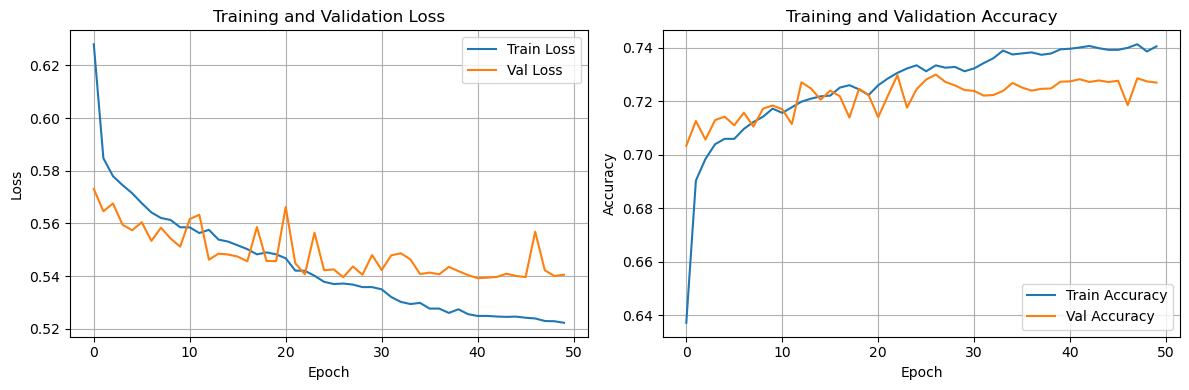

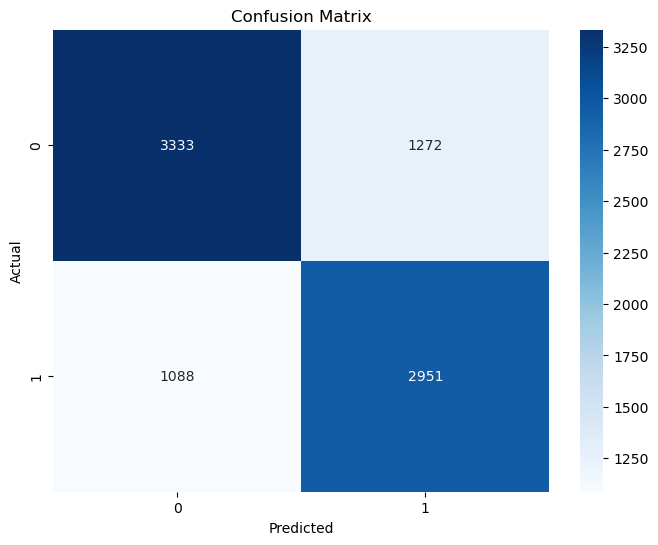


Training complete! Best validation accuracy: 0.7300
Best model saved at: best_model_test.pth


In [11]:


train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = torch.utils.data.random_split(dataset, [train_size, val_size])


train_loader = DataLoader(CustomDataset(train_dataset), batch_size=64, shuffle=True, num_workers=0)
val_loader = DataLoader(CustomDataset(val_dataset), batch_size=64, shuffle=False, num_workers=0)

model = DeepUVModel(
    tabular_input_dim=4,
    tabular_hidden_dims=[64, 32], 
    image_size=224,
    patch_size=32, 
    vit_dim=384,   
    vit_depth=6,    
    vit_heads=6,
    vit_mlp_dim=1536,
    num_classes=2
).to(device)




criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=5e-5, weight_decay=0.01)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)


scaler = GradScaler() if torch.cuda.is_available() else None

num_epochs = 50
best_val_acc = 0.0
best_model_path = 'best_model_test.pth'


train_losses = []
val_losses = []
train_accs = []
val_accs = []


for epoch in range(num_epochs):
    print(f"\nEpoch {epoch+1}/{num_epochs}")
    print("-" * 50)
    
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device, scaler)
    
    val_loss, val_acc, val_precision, val_recall, val_f1, val_labels, val_preds = validate_epoch(
        model, val_loader, criterion, device
    )
    
    scheduler.step(val_loss)
    
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)
    
    print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")
    print(f"Val Precision: {val_precision:.4f}, Val Recall: {val_recall:.4f}, Val F1: {val_f1:.4f}")
    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_acc': val_acc,
            'val_f1': val_f1
        }, best_model_path)
        print(f"Saved best model with validation accuracy: {val_acc:.4f}")

plot_training_curves(train_losses, val_losses, train_accs, val_accs)

plot_confusion_matrix(val_labels, val_preds)

print(f"\nTraining complete! Best validation accuracy: {best_val_acc:.4f}")
print(f"Best model saved at: {best_model_path}")